# 01 — EDA y calidad de datos (E1)
**AppleVision Chile — MLY1101**

Datos: `data/02_processed/metricas.csv`, generado con `python -m src.vision.detector --modelo models/best.pt --video reports/prueba_cinta_con_panel.mp4`. El detector ya descarta detecciones cortadas por el borde, con máscara fallida, con `area_px < 3000`, `aspecto < 0.60` o hue fuera de rojo.

## 1. Carga de datos

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style='whitegrid')

ruta = Path('../data/02_processed/metricas.csv')
df = pd.read_csv(ruta)
VARS = ['area_px', 'diametro_mm_est', 'hue', 'saturacion', 'aspecto']
df.head()

,id,frame,area_px,diametro_mm_est,hue,saturacion,valor,aspecto,clase_yolo
0,4,6,12422,39.30,10.39,148.65,139.23,0.7197,apple
1,8,7,8245,32.02,12.08,150.78,144.92,0.8103,apple
2,4,8,12128,38.83,9.29,146.64,153.36,0.7290,apple
3,10,9,7823,31.19,7.71,152.77,148.37,0.8722,apple
4,8,9,8508,32.53,10.69,144.36,159.74,0.8288,apple


## 2. Visión general

In [2]:
print('Dimensiones:', df.shape)
print('Manzanas únicas (id):', df['id'].nunique(), '| frames:', df['frame'].nunique())
print(df.dtypes)
print('\nObservaciones por manzana:'); print(df['id'].value_counts().sort_index())
print('\nClase YOLO:'); print(df['clase_yolo'].value_counts())

Dimensiones: (38, 9)
Manzanas únicas (id): 4 | frames: 31
id                   int64
frame                int64
area_px              int64
diametro_mm_est    float64
hue                float64
saturacion         float64
valor              float64
aspecto            float64
clase_yolo             str
dtype: object

Observaciones por manzana:
id
4     13
8     15
9      6
10     4
Name: count, dtype: int64

Clase YOLO:
clase_yolo
apple    38
Name: count, dtype: int64


## 3. Calidad de datos

In [3]:
print('Nulos por columna:'); print(df.isna().sum())
print('Duplicados (id, frame):', df.duplicated(['id', 'frame']).sum())
print('Valores <= 0 en variables continuas:', int((df[VARS] <= 0).sum().sum()))
assert df['aspecto'].between(0, 1).all(), 'aspecto fuera de [0,1]'

Nulos por columna:
id                 0
frame              0
area_px            0
diametro_mm_est    0
hue                0
saturacion         0
valor              0
aspecto            0
clase_yolo         0
dtype: int64
Duplicados (id, frame): 0
Valores <= 0 en variables continuas: 0


## 4. Estadística descriptiva y distribuciones

In [4]:
df[VARS].describe().round(2)

,area_px,diametro_mm_est,hue,saturacion,aspecto
count,38.00,38.00,38.00,38.00,38.00
mean,10421.84,35.52,14.45,141.68,0.86
std,3387.89,5.95,5.39,9.83,0.10
min,3697.00,21.44,5.79,113.22,0.62
25%,7797.50,31.14,9.83,134.43,0.79
50%,10244.50,35.68,14.14,143.26,0.84
75%,12647.50,39.65,18.08,148.16,0.95
max,18406.00,47.84,24.56,158.87,0.99


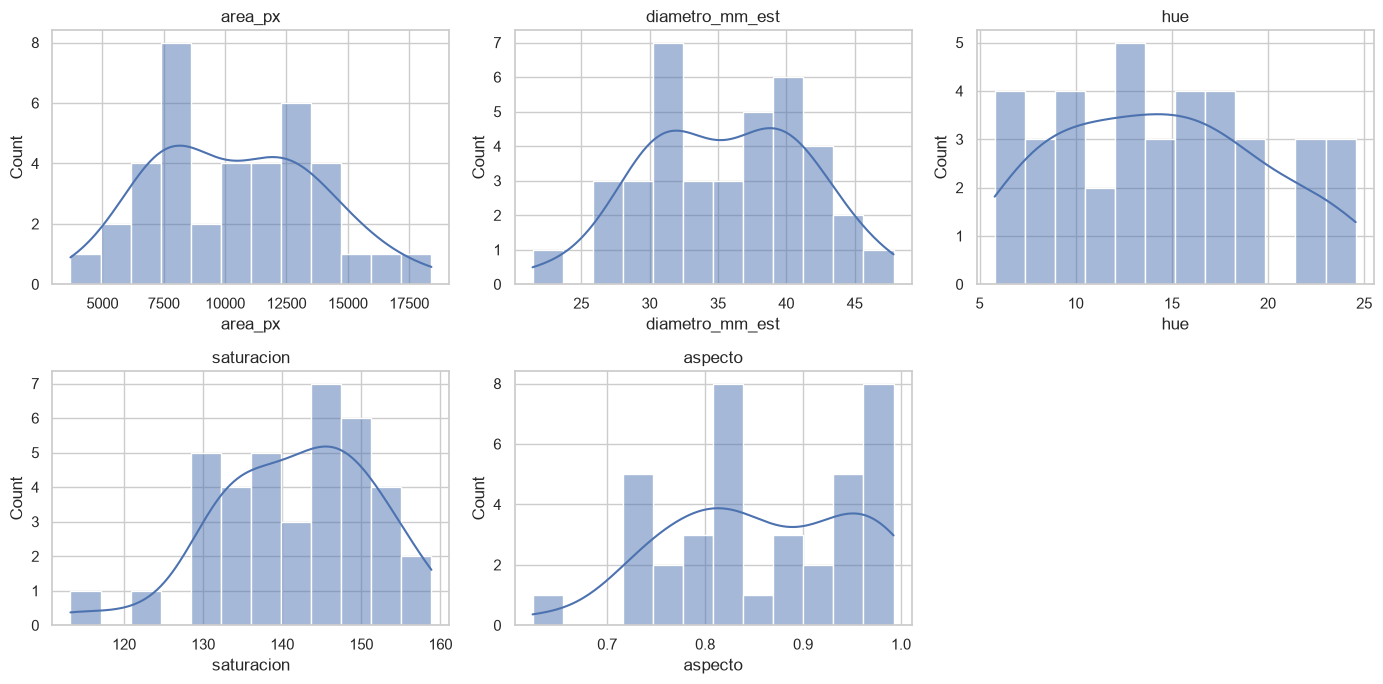

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(14, 7))
for ax, v in zip(axs.ravel(), VARS):
    sns.histplot(df[v], kde=True, bins=12, ax=ax); ax.set_title(v)
axs.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

## 5. Outliers
Boxplots y regla IQR. Se comprueba además que los filtros del detector cumplen: `area_px >= 3000`, `aspecto >= 0.60` y hue rojo (`<= 25` o `>= 165`). El hue rojo es circular (cerca de 0 y 179); aquí todo queda en el lado bajo.

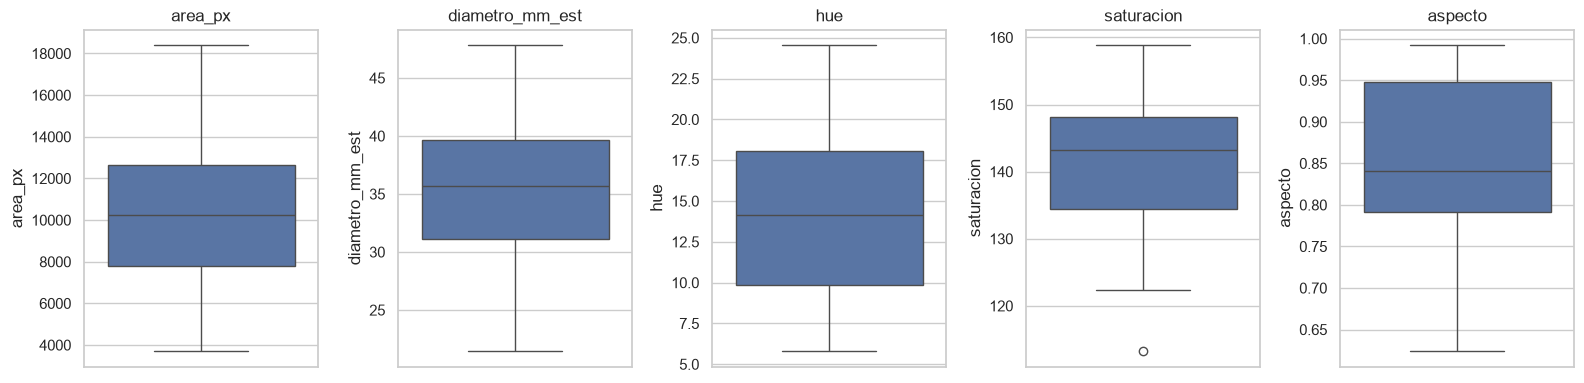

Outliers IQR por variable:
area_px            0
diametro_mm_est    0
hue                0
saturacion         1
aspecto            0
dtype: int64

area_px min: 3697 (>= 3000: True )
aspecto min: 0.6238 (>= 0.60: True )
hue rango: 5.79 - 24.56 (rojo: True )


In [6]:
fig, axs = plt.subplots(1, 5, figsize=(16, 4))
for ax, v in zip(axs, VARS):
    sns.boxplot(y=df[v], ax=ax); ax.set_title(v)
plt.tight_layout(); plt.show()

q1, q3 = df[VARS].quantile(.25), df[VARS].quantile(.75)
iqr = q3 - q1
fuera = ((df[VARS] < q1 - 1.5*iqr) | (df[VARS] > q3 + 1.5*iqr)).sum()
print('Outliers IQR por variable:'); print(fuera)
print('\narea_px min:', df['area_px'].min(), '(>= 3000:', df['area_px'].min() >= 3000, ')')
print('aspecto min:', df['aspecto'].min(), '(>= 0.60:', df['aspecto'].min() >= 0.60, ')')
print('hue rango:', df['hue'].min(), '-', df['hue'].max(), '(rojo:', bool(((df['hue'] <= 25) | (df['hue'] >= 165)).all()), ')')

## 6. Correlaciones

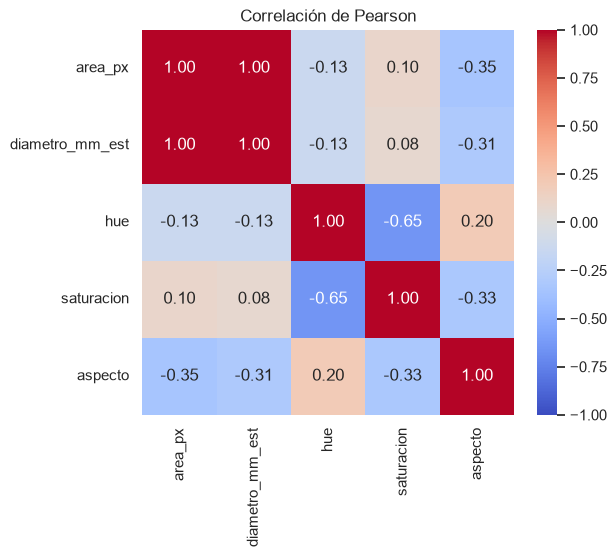

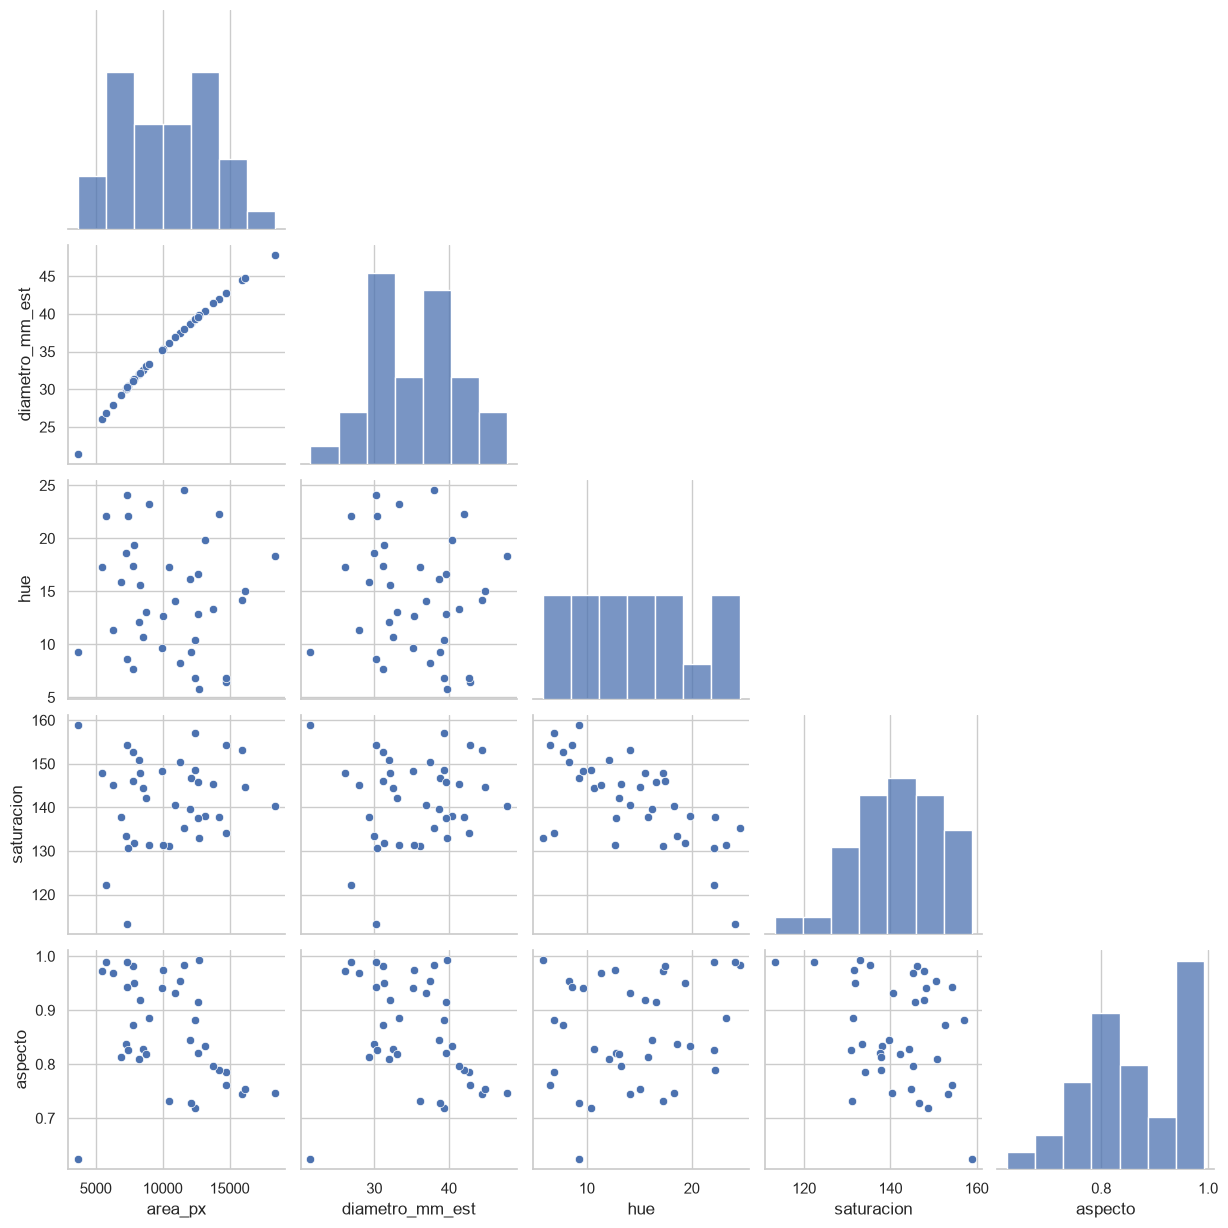

In [7]:
corr = df[VARS].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación de Pearson'); plt.show()
sns.pairplot(df[VARS], corner=True); plt.show()

**Lectura:** `area_px` y `diametro_mm_est` tienen correlación ≈ 1 porque el diámetro se calcula directo del área (`d = 2·√(A/π)/px_por_mm`): son la misma información, usar solo una como feature. Hue y saturación se correlacionan negativamente (~ -0.65).

## 7. Calibre y color frente a la norma

In [8]:
CAL_MIN, CAL_MAX = 65, 80   # config.yaml (calibre de exportación, mm)
d = df['diametro_mm_est']
print(f'Calibre estimado: {d.min():.1f} - {d.max():.1f} mm (media {d.mean():.1f})')
print('Dentro de 65-80 mm:', int(d.between(CAL_MIN, CAL_MAX).sum()), 'de', len(d))
print('Bajo 65 mm:', int((d < CAL_MIN).sum()))
por_id = df.groupby('id')[['diametro_mm_est', 'hue', 'saturacion']].mean().round(1)
por_id['n_obs'] = df.groupby('id').size()
por_id

Calibre estimado: 21.4 - 47.8 mm (media 35.5)
Dentro de 65-80 mm: 0 de 38
Bajo 65 mm: 38


,diametro_mm_est,hue,saturacion,n_obs
id,,,,
4,40.2,13.5,142.6,13
8,33.7,15.8,141.0,15
9,28.9,16.4,138.9,6
10,37.0,9.6,145.5,4


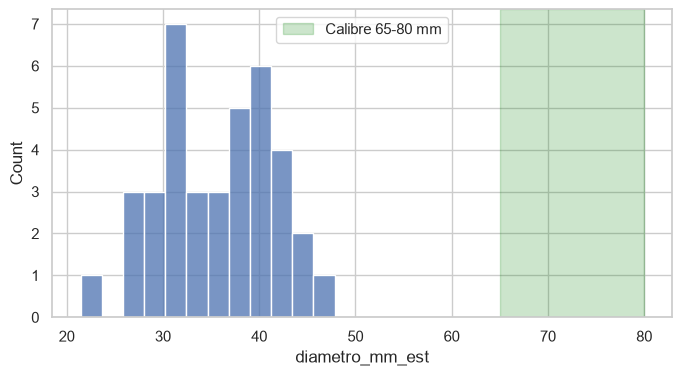

In [9]:
plt.figure(figsize=(8, 4))
sns.histplot(d, bins=12)
plt.axvspan(CAL_MIN, CAL_MAX, color='green', alpha=.2, label='Calibre 65-80 mm')
plt.xlabel('diametro_mm_est'); plt.legend(); plt.show()

## 8. Conclusiones y recomendaciones

**Calidad de los datos**
- 38 observaciones sin nulos ni duplicados, tras aplicar los filtros de calidad en el detector. No quedan áreas diminutas ni hue fuera de rojo.
- Solo **4 manzanas distintas** (ids 4, 8, 9, 10) y una clase YOLO. Las filas del mismo `id` en distintos frames **no son independientes**: al entrenar, dividir por `id`, no por fila, para evitar fuga de datos.
- Es un único video corto: sirve para validar el pipeline, no para inferir distribuciones de una partida real.

**Calibre (norma de exportación 65-80 mm)**
- El diámetro estimado va de ~21 a ~48 mm: **ninguna observación llega a 65 mm**. Con este resultado todo se clasificaría fuera de calibre.
- Es casi seguro un problema de escala, no de fruta: `px_por_mm = 3.2` en `config.yaml` es un valor provisional. **Recalibrar con un objeto de diámetro conocido** (`calibrar_escala(ancho_px, diametro_real_mm)`) antes de usar el calibre para decidir. No se debe reportar distribución de calibres hasta entonces.
- Además, la ROI de YOLO puede no cubrir bien la fruta; el diámetro depende de la máscara HSV.

**Color**
- Hue entre ~6 y ~25 y saturación ~113-159: tonos rojos a naranja-rojizos. El filtro de hue (<= 25) puede excluir manzanas amarillentas o verdes legítimas; conviene ajustarlo si se van a clasificar variedades no rojas.
- Con hue y saturación correlacionados (-0.65), el color puede resumirse con ambos sin perder mucho, pero no son independientes.

**Recomendaciones**
1. Recalibrar `px_por_mm` con un patrón y repetir este EDA.
2. Capturar más videos/partidas (más manzanas por categoría) antes de modelar.
3. Mantener los filtros del detector (borde, área, aspecto, hue) para que el CSV no se contamine con objetos cortados.
4. Contrastar con la norma SAG/Asoex vigente antes de usar los umbrales de calibre y color como criterio comercial; los de `config.yaml` son los del proyecto, no los verifiqué contra la norma.